# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SeasonetDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import math
import csv
import matplotlib.pyplot as plt

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir": "./data/seasonet/",
}
dataset = SeasonetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1759830


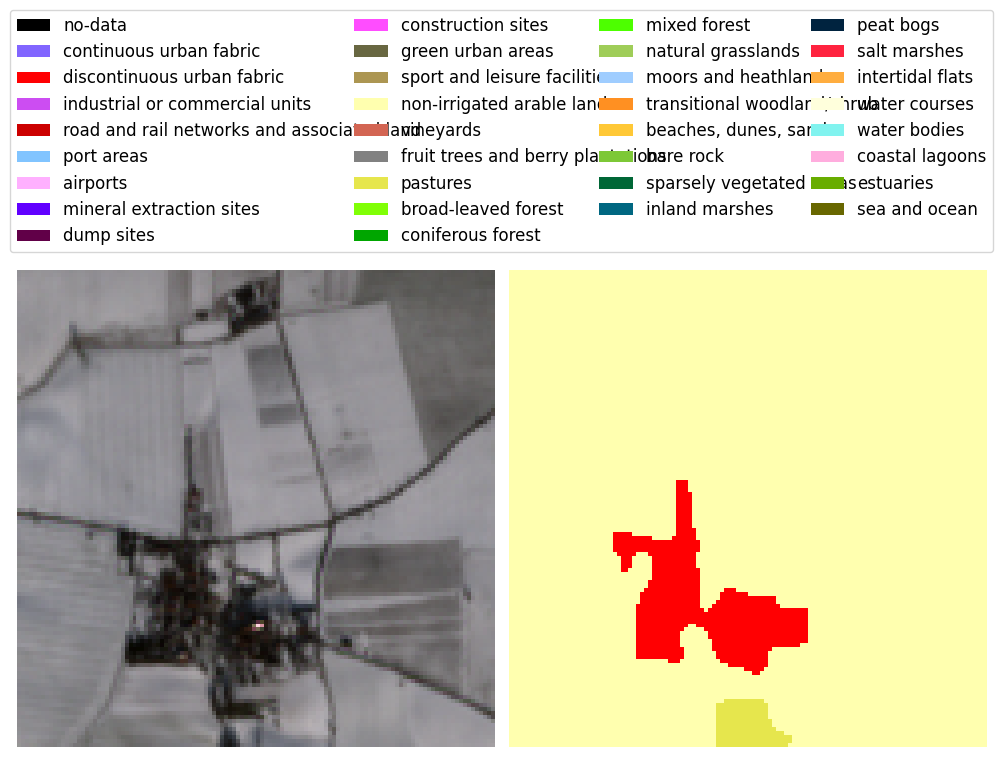

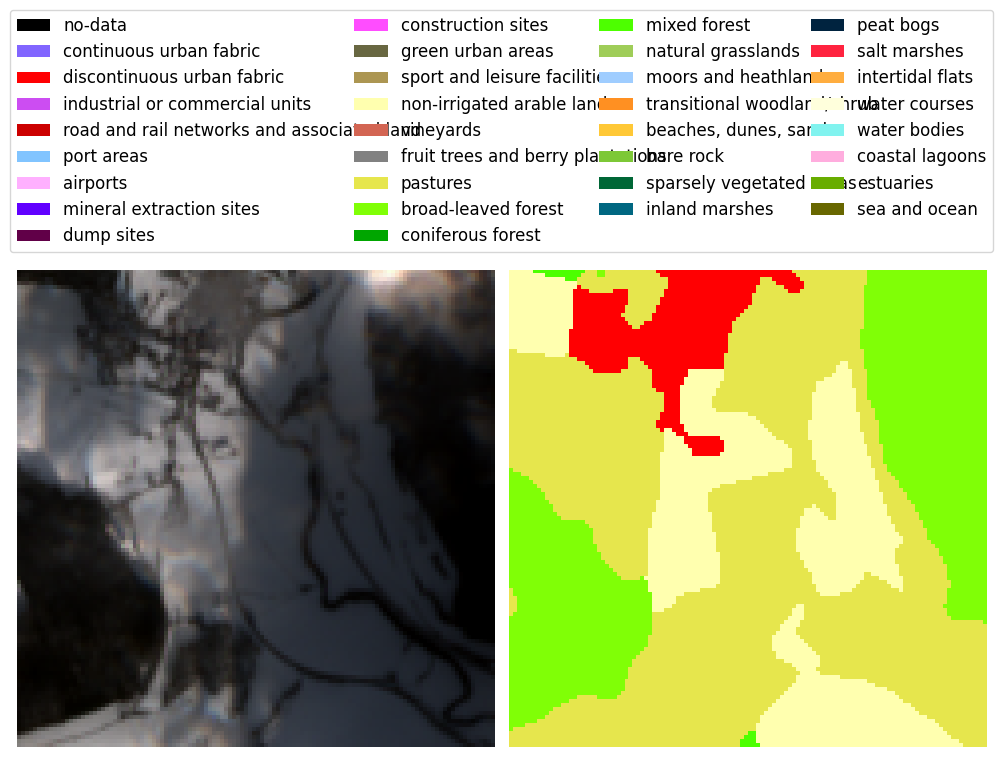

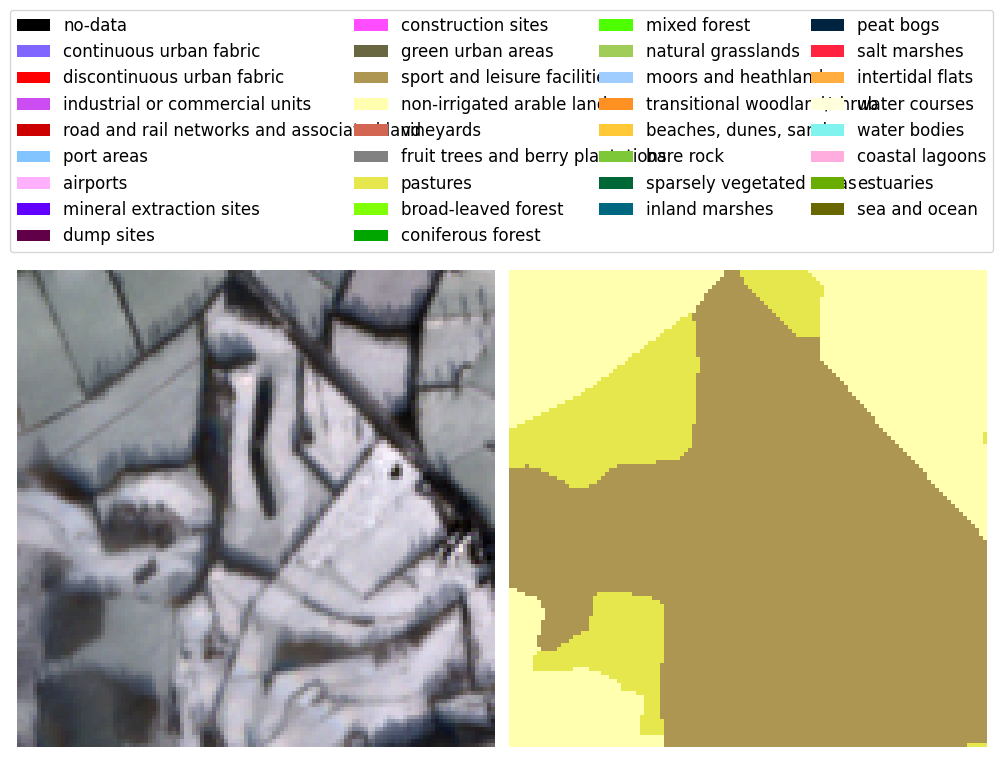

In [8]:
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [14]:
dataset.data_distribution_table()

,Number of pixels
no-data,0.000000e+00
continuous urban fabric,4.662084e+07
discontinuous urban fabric,1.248124e+09
industrial or commercial units,3.124962e+08
road and rail networks and associated land,4.836635e+07
port areas,2.024114e+06
airports,1.834837e+07
mineral extraction sites,5.263014e+07
dump sites,1.136950e+07
construction sites,4.402311e+06


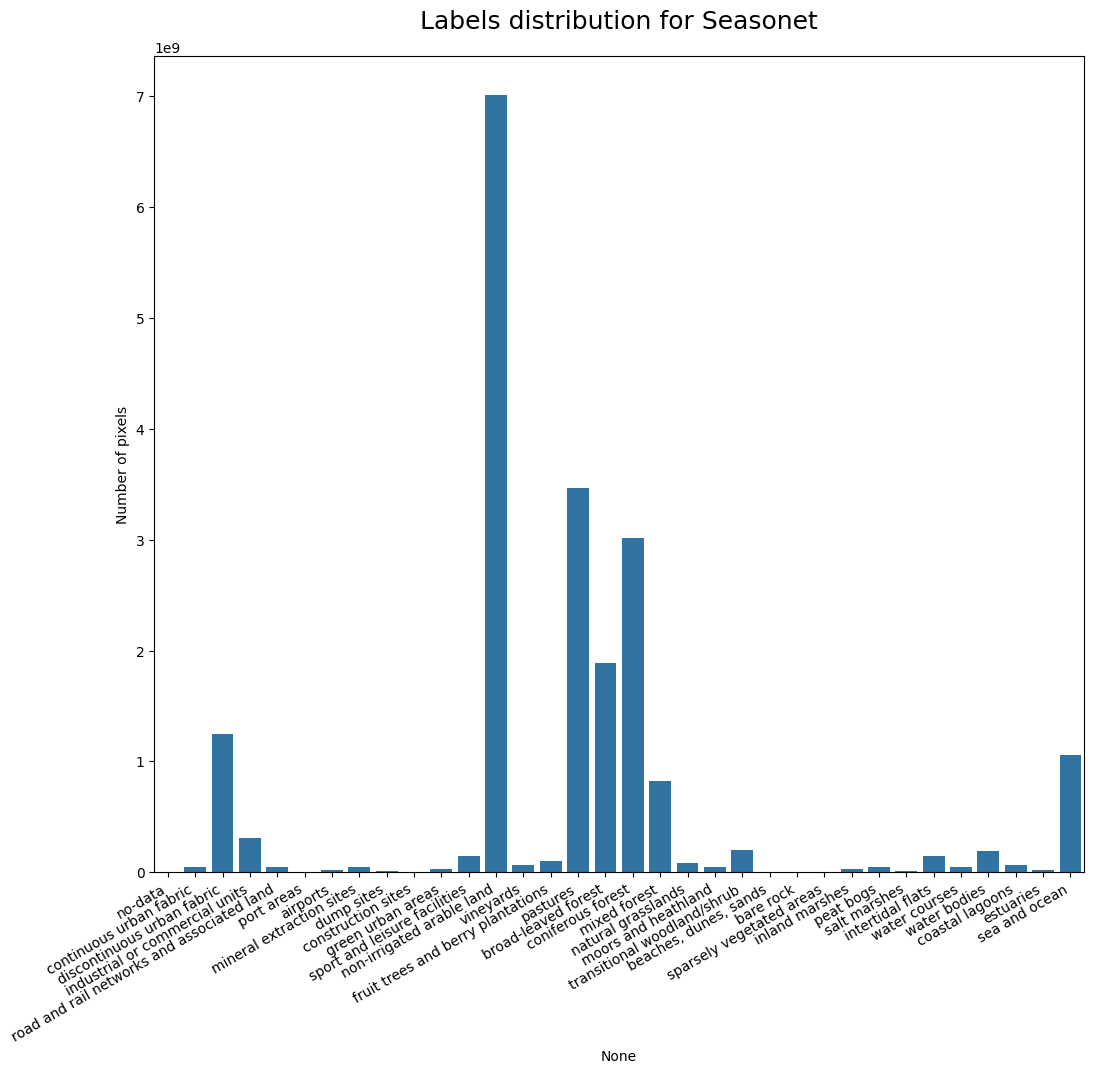

In [15]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/seasonet",
    "csv_file": "./data/seasonet/seasonet_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SeasonetDataset(train_dataset_config)
len(train_dataset)

1407864

## Create the model

In [ ]:
epochs = 1
model_directory = "./data/experiments/seasonet"
model_config = {
    "num_classes": 34, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [16]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-18 20:57:42,210 INFO Starting training.
training: 100%|██████████| 43996/43996 [5:29:54<00:00,  2.22it/s]
2025-11-19 02:27:36,830 INFO epoch: 1, time: 19794, loss:  0.64709
testing on train set: 100%|██████████| 43996/43996 [3:15:22<00:00,  3.75it/s]  
2025-11-19 05:43:02,099 INFO IOU:0.21261559548240366, IOU mean:0.021920109290981503, IOU per Class:[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.33533905 0.         0.         0.1325136  0.         0.0931059
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.18432517]
2025-11-19 05:43:04,420 INFO Train loss: [0.6438637701104571]
2025-11-19 05:43:04,421 INFO Validation loss: []
2025-11-19 05:43:04,422 INFO Train time per epochs: [19794]
2025-11-19 05:43:04,422 INFO Finished training. training time: 19794


## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/seasonet",
    "csv_file": "./data/seasonet/seasonet_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SeasonetDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/seasonet/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

175983


2025-11-18 13:51:59,132 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/seasonet/checkpoint.pth.tar
2025-11-18 13:51:59,538 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/seasonet/checkpoint.pth.tar at epoch 2
testing on test set: 100%|██████████| 43996/43996 [24:44<00:00, 29.64it/s] 


[{'IOU': 0.5863099630022858,
  'IOU mean': 0.11476372987510193,
  'IOU per Class': array([0.        , 0.        , 0.55609379, 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.73863902, 0.        , 0.        ,
         0.49182125, 0.56281186, 0.69008545, 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.86251544])}]

## Predictions

In [4]:
'''
The predictions will give 34 masks (one per class). 
This function rearranges the figure to make it more readable.
'''
def rearrange_figure_to_grid(fig, cols=8):
    original_axes = fig.axes
    num_plots = len(original_axes)
    rows = math.ceil(num_plots / cols)

    # Create a new figure
    new_fig, new_axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    new_axes = new_axes.flatten()

    for i, old_ax in enumerate(original_axes):
        # Extract the image and title
        im = old_ax.images[0] if old_ax.images else None
        title = old_ax.get_title()

        # Copy to new axis
        if im:
            new_axes[i].imshow(im.get_array(), cmap=im.get_cmap())
            new_axes[i].set_title(title, fontsize=13)
        new_axes[i].axis('off')

    # Turn off any unused subplots
    for j in range(i + 1, len(new_axes)):
        new_axes[j].axis('off')

    plt.tight_layout()
    return new_fig

2025-11-19 07:56:23,853 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/seasonet/checkpoint.pth.tar
2025-11-19 07:56:24,311 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/seasonet/checkpoint.pth.tar at epoch 2


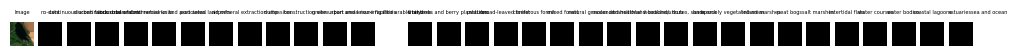

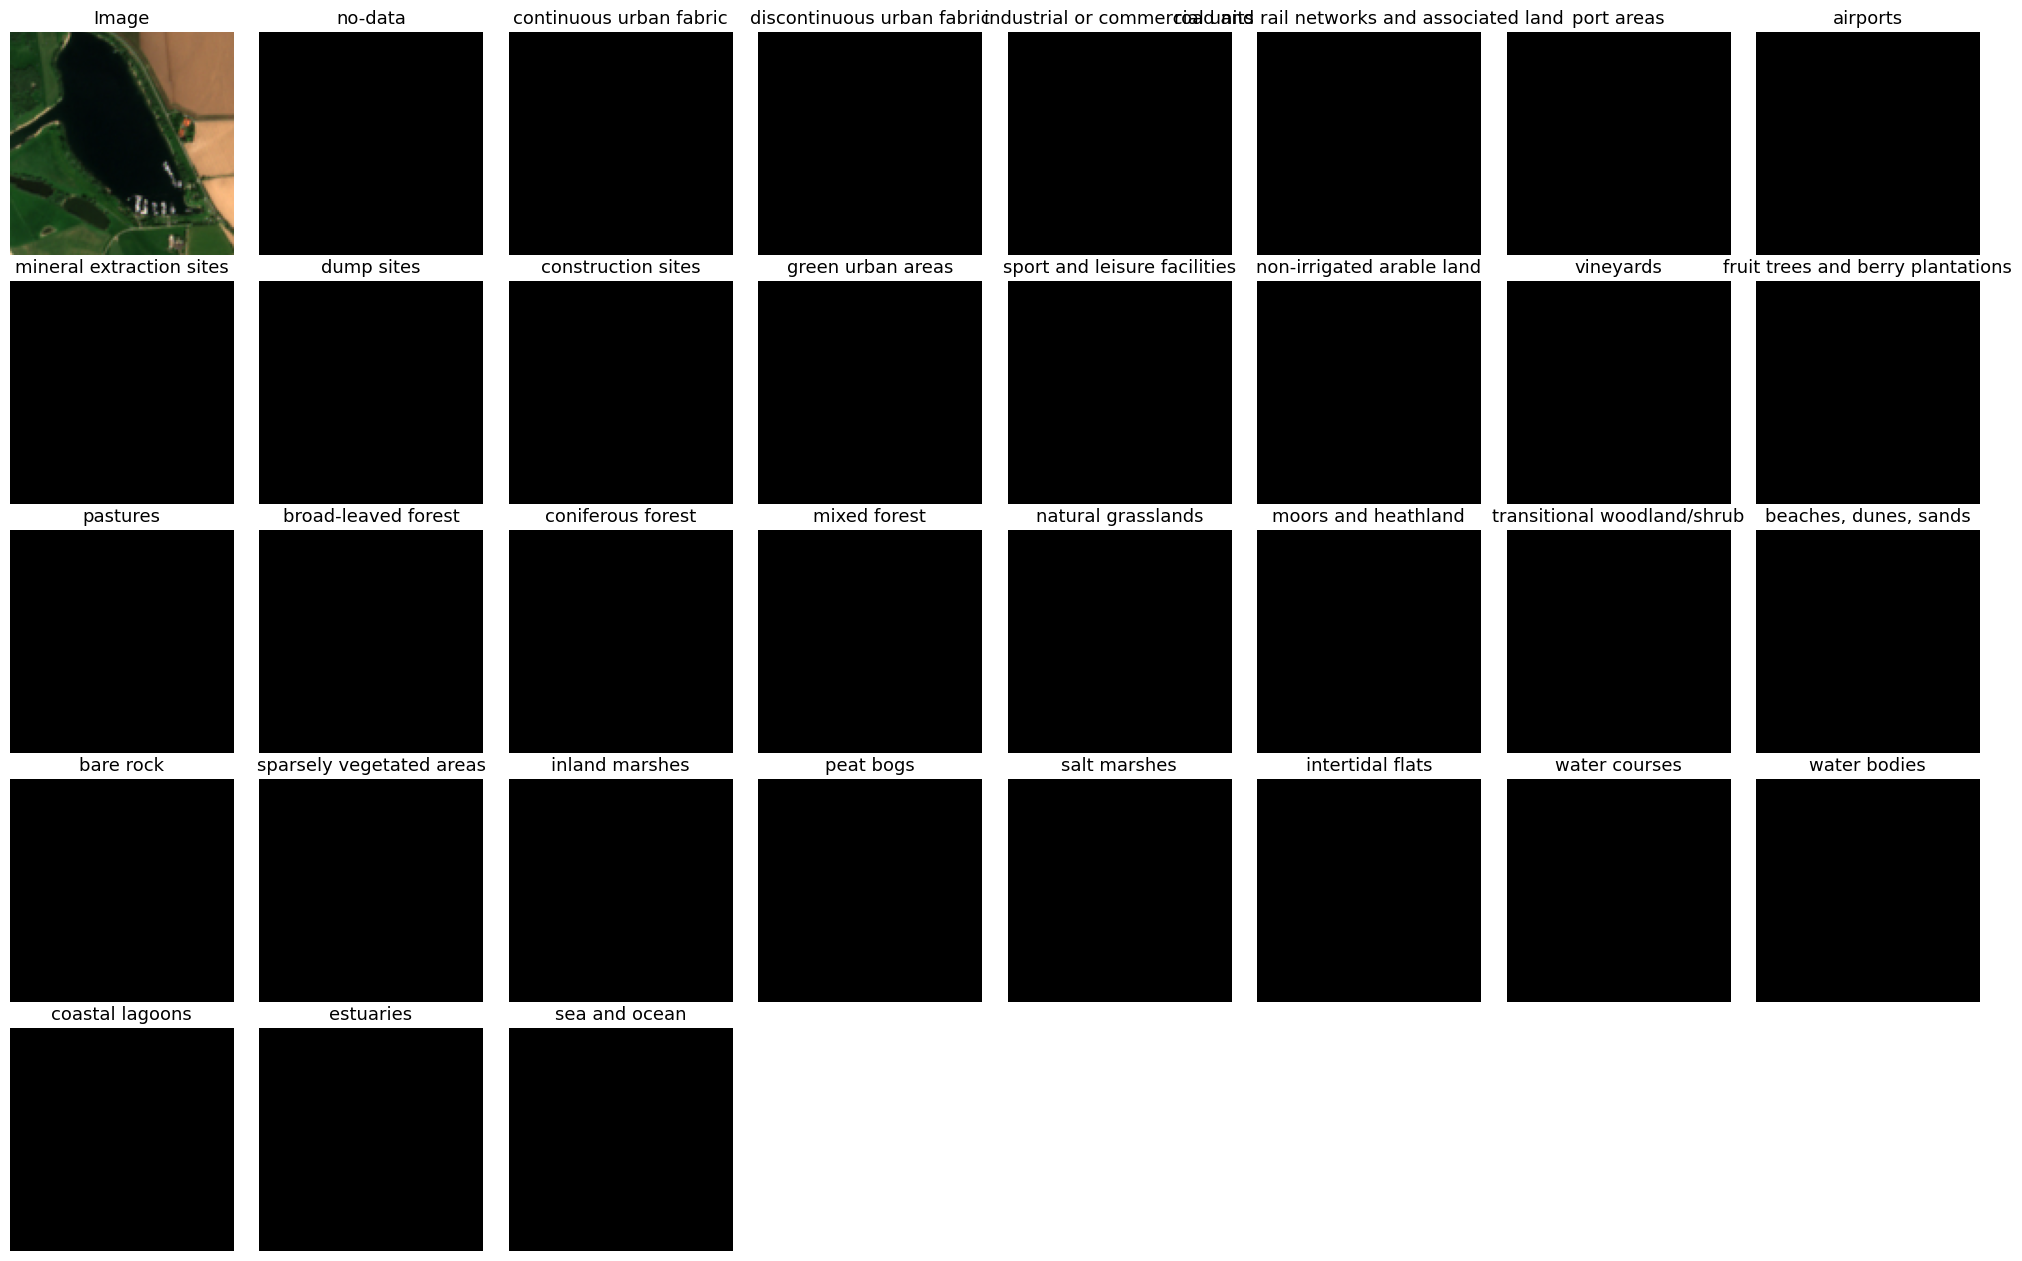

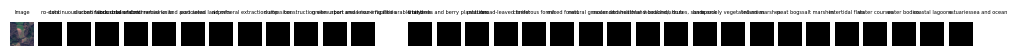

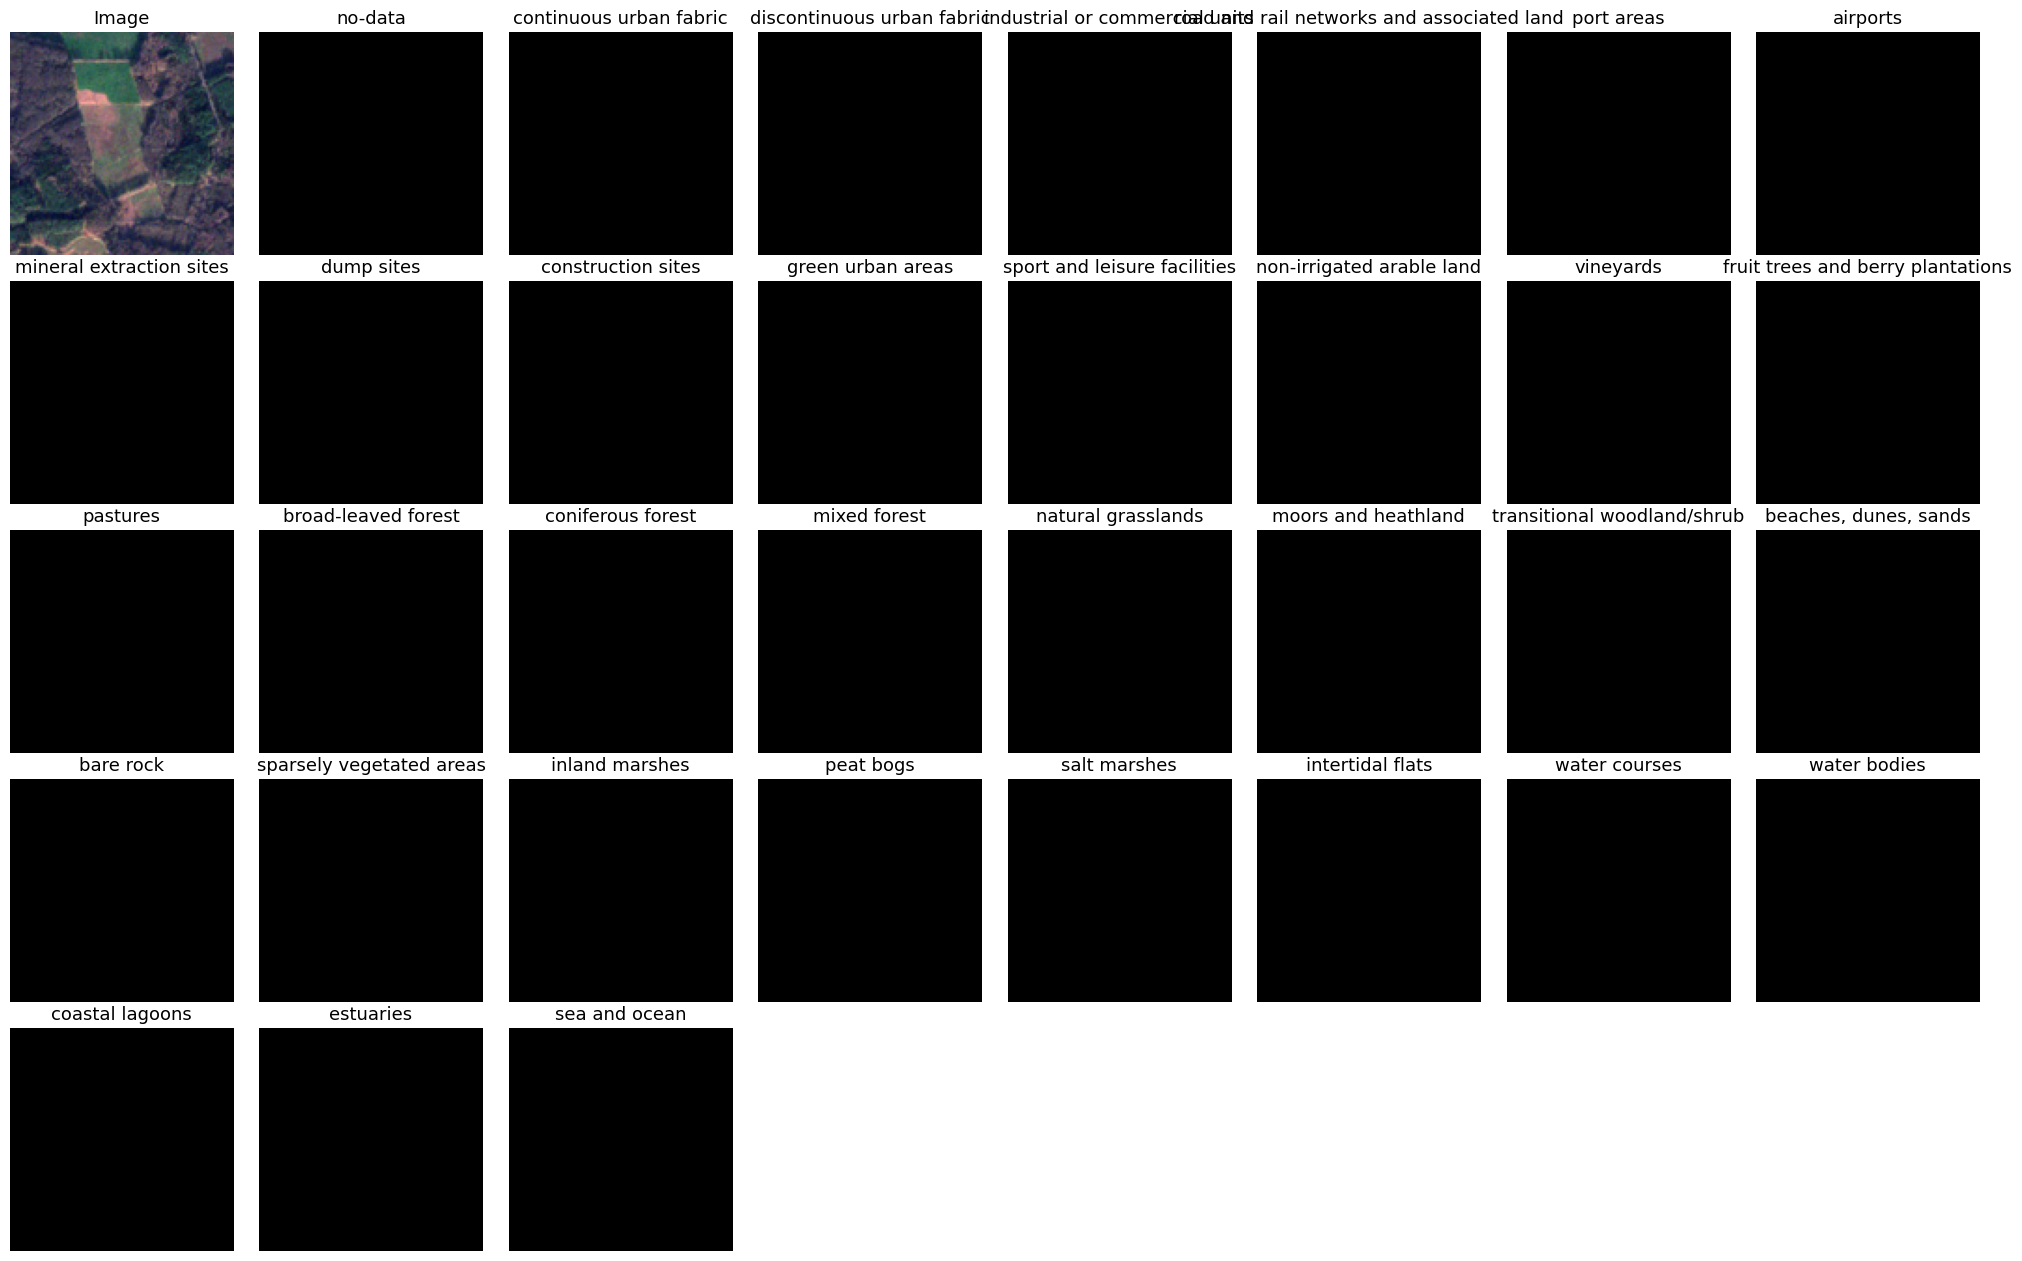

In [ ]:
model_path = "./data/experiments/seasonet/checkpoint.pth.tar"
labels = ["no-data","continuous urban fabric","discontinuous urban fabric","industrial or commercial units",
          "road and rail networks and associated land","port areas","airports","mineral extraction sites",
          "dump sites","construction sites","green urban areas","sport and leisure facilities","non-irrigated arable land",
          "vineyards","fruit trees and berry plantations","pastures","broad-leaved forest","coniferous forest",
          "mixed forest","natural grasslands","moors and heathland","transitional woodland/shrub","beaches, dunes, sands",
          "bare rock","sparsely vegetated areas","inland marshes","peat bogs","salt marshes","intertidal flats","water courses",
          "water bodies","coastal lagoons","estuaries","sea and ocean"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 3})

csv_file = "./data/seasonet/seasonet_test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/seasonet/images/' + test_list[1])
image = (image - image.min()) / (image.max() - image.min())
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()

image = image_loader('./data/seasonet/images/' + test_list[50])
image = (image - image.min()) / (image.max() - image.min())
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()